# Tic-Tac-Toe Demo

## Understanding Adversarial Games and Optimization Algorithms

### What is Tic-Tac-Toe?
**Tic-Tac-Toe** is a classic paper-and-pencil game for two players, **X** and **O**, who take turns marking the spaces in a $3 \times 3$ grid. The player who succeeds in placing three of their marks in a horizontal, vertical, or diagonal row wins the game. If all 9 squares are filled without any player achieving this, the game is a draw (or tie).

### Adversarial Games
In artificial intelligence, Tic-Tac-Toe belongs to a category of games called **adversarial search problems**. These are characterized as:
* **Two-Player**: Two opposing forces play against each other.
* **Turn-Based**: Players alternate moves.
* **Zero-Sum**: One player's gain is the other player's loss (e.g., if one player wins $+10$, the other loses $-10$).
* **Perfect Information**: Both players can see the entire state of the board at any given time.

---

### 1. Drawing a Tic-Tac-Toe Board
To programmatically solve or analyze the game, we represent the state of the board as a flat list of 9 elements. Using tools like **Graphviz**, we can visually render these list structures as intuitive $3 \times 3$ HTML tables to follow how moves progress step-by-step.





In [24]:
import graphviz
import copy

In [25]:
def get_board(board_state):
    """
    Generates an HTML table label representation of a Tic Tac Toe board for Graphviz.
    """
    # Ensure empty cells have non-breaking spaces for proper rendering
    display_state = [val if val.strip() != '' else '&nbsp;' for val in board_state]

    html_table = f"""<
    <TABLE BORDER="0" CELLBORDER="1" CELLSPACING="0" CELLPADDING="8">
      <TR>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[0]}</TD>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[1]}</TD>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[2]}</TD>
      </TR>
      <TR>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[3]}</TD>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[4]}</TD>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[5]}</TD>
      </TR>
      <TR>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[6]}</TD>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[7]}</TD>
        <TD WIDTH="20" HEIGHT="20" ALIGN="CENTER">{display_state[8]}</TD>
      </TR>
    </TABLE>
    >"""
    return html_table

# Alias get_board_html to get_board so that game_tree continues to work seamlessly
get_board_html = get_board

1. Drawing the single root board:


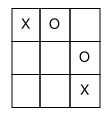


2. Drawing the game tree from the root board:


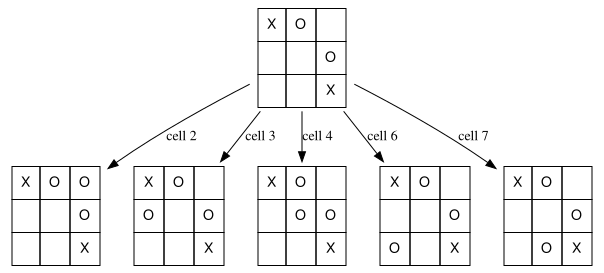

In [26]:
def draw_root_board(board_state):
    """
    Draw and display a single Tic Tac Toe board from board_state.
    """
    import graphviz
    dot = graphviz.Graph('SingleBoard', comment='Single Tic Tac Toe Board')
    dot.attr('node', fontname='Helvetica', shape='none')

    # Normalize the board state
    board_state = [x if x != '' else ' ' for x in board_state]

    dot.node('board', label=get_board(board_state))
    return dot

def game_tree(root_state, current_player='X', parent_id='root', node_registry=None):
    """
    Create a 1-level decision tree from the root_state and return:
    1. The Graphviz Digraph object
    2. A dict (node_registry) storing the board state of each node as:
       { node_id: board_state }
    """

    if node_registry is None:
        node_registry = {}

    dot = graphviz.Digraph('GameTree', comment='Tic Tac Toe Game Tree')
    dot.attr(rankdir='TB')
    dot.attr('node', fontname='Helvetica', shape='none')

    # Normalize the root state
    root_state = [x if x != '' else ' ' for x in root_state]

    # Register and draw the root node
    node_registry[parent_id] = root_state
    dot.node(parent_id, label=get_board_html(root_state))

    # Find empty spots
    empty_indices = [i for i, val in enumerate(root_state) if val.strip() == '']

    # Create and link child nodes
    for idx, empty_idx in enumerate(empty_indices):
        child_state = copy.deepcopy(root_state)
        child_state[empty_idx] = current_player

        child_id = f"{parent_id}_child_{idx}"
        node_registry[child_id] = child_state

        dot.node(child_id, label=get_board(child_state))
        dot.edge(parent_id, child_id, label=f'cell {empty_idx}')

    return dot, node_registry

# --- Demo usage of the two new functions ---
root_board = [
    'X', 'O', ' ',
    ' ', ' ', 'O',
    ' ', ' ', 'X'
]

# 1. Draw a single root board
print("1. Drawing the single root board:")
single_board_graph = draw_root_board(root_board)
display(single_board_graph)

# 2. Draw the game tree from that root board and register child nodes
print("\n2. Drawing the game tree from the root board:")
tree_graph, registry = game_tree(root_board, current_player='O')
display(tree_graph)

By using `registry`, you can take any child node (e.g., `registry['root_child_0']`) as the new root state and continue passing it to the function to draw deeper branches.

3. Iterating through children nodes and drawing their subsequent trees:

Sub-tree originating from node 'root_child_0' (State: ['X', 'O', 'O', ' ', ' ', 'O', ' ', ' ', 'X']):


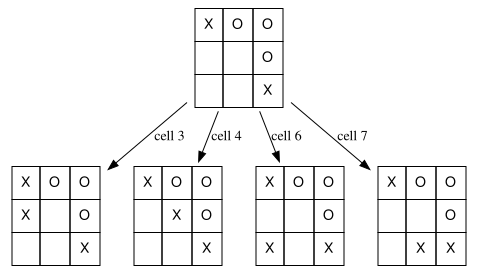


Sub-tree originating from node 'root_child_1' (State: ['X', 'O', ' ', 'O', ' ', 'O', ' ', ' ', 'X']):


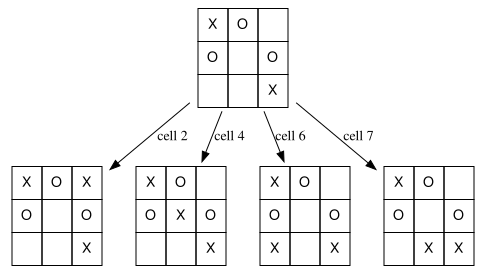


Sub-tree originating from node 'root_child_2' (State: ['X', 'O', ' ', ' ', 'O', 'O', ' ', ' ', 'X']):


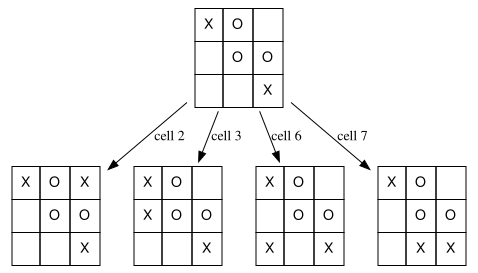


Sub-tree originating from node 'root_child_3' (State: ['X', 'O', ' ', ' ', ' ', 'O', 'O', ' ', 'X']):


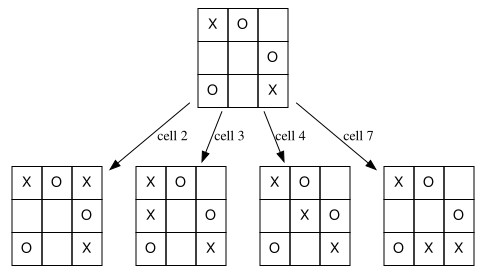


Sub-tree originating from node 'root_child_4' (State: ['X', 'O', ' ', ' ', ' ', 'O', ' ', 'O', 'X']):


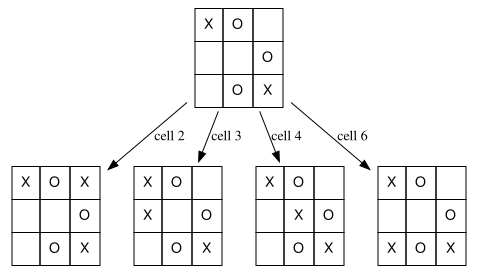

In [27]:
# 3. Iterate through each child node and draw its next possible moves (children)
print("3. Iterating through children nodes and drawing their subsequent trees:")

# We filter the registry to get only the child nodes from our previous generation
child_keys = [key for key in registry.keys() if key != 'root']

# For each child state, we can visualize the next turn.
# Since the previous turn was 'O' (player 'O' moved), the next player to move is 'X'.
for child_id in child_keys:
    child_state = registry[child_id]
    print(f"\nSub-tree originating from node '{child_id}' (State: {child_state}):")

    # Generate next moves for 'X'
    branch_graph, branch_registry = game_tree(
        root_state=child_state,
        current_player='X',
        parent_id=child_id
    )
    display(branch_graph)

### 2. The Minimax Algorithm

The **Minimax algorithm** is a recursive decision-making algorithm used in game theory and AI for choosing the optimal move in a two-player, zero-sum game.
* **Maximizing Player (O/Computer)**: Tries to choose the move that yields the highest possible score ($+10$).
* **Minimizing Player (X/Human)**: Tries to choose the move that yields the lowest possible score ($-10$).

The algorithm performs a depth-first search of the entire game tree. At each step, it backtracks up the tree, passing the optimal values of the child states to their parent nodes.

In [28]:
def check_winner(board):
    """
    Checks the board state and returns:
    'X' if X wins, 'O' if O wins, 'Tie' if it's a tie, None otherwise.
    """
    win_patterns = [
        [0, 1, 2], [3, 4, 5], [6, 7, 8], # Rows
        [0, 3, 6], [1, 4, 7], [2, 5, 8], # Columns
        [0, 4, 8], [2, 4, 6]             # Diagonals
    ]
    for pattern in win_patterns:
        if board[pattern[0]] != ' ' and board[pattern[0]] == board[pattern[1]] == board[pattern[2]]:
            return board[pattern[0]]

    if ' ' not in board:
        return 'Tie'

    return None

def minimax(board, depth, is_maximizing):
    """
    Minimax algorithm implementation.
    Returns the evaluation score of the board position.
    Computer is 'O' (Maximizing, tries to reach +10),
    Human is 'X' (Minimizing, tries to reach -10).
    """
    # Handle space padding normalization internally
    clean_board = [x if x != '' else ' ' for x in board]
    winner = check_winner(clean_board)

    if winner == 'O':
        return 10 - depth
    if winner == 'X':
        return depth - 10
    if winner == 'Tie':
        return 0

    if is_maximizing:
        best_score = float('-inf')
        for i in range(9):
            if clean_board[i] == ' ':
                clean_board[i] = 'O'
                score = minimax(clean_board, depth + 1, False)
                clean_board[i] = ' '
                best_score = max(score, best_score)
        return best_score
    else:
        best_score = float('inf')
        for i in range(9):
            if clean_board[i] == ' ':
                clean_board[i] = 'X'
                score = minimax(clean_board, depth + 1, True)
                clean_board[i] = ' '
                best_score = min(score, best_score)
        return best_score

Visualizing Minimax decision layers starting from root:


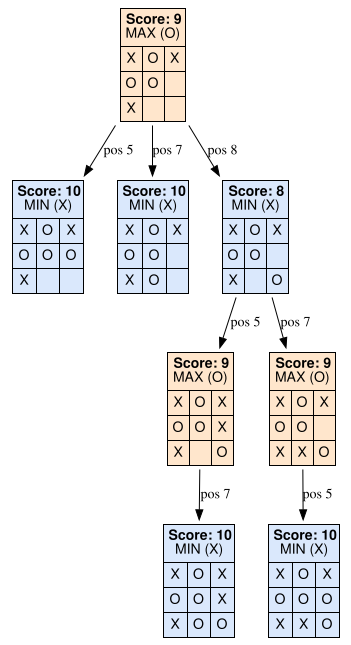

In [29]:
def visualize_minimax_tree(root_state, current_player):
    """
    Generates a full decision tree showing minimax values and layer goals.
    """
    dot = graphviz.Digraph('MinimaxTree', comment='Minimax Decision Tree')
    dot.attr(rankdir='TB')
    dot.attr('node', fontname='Helvetica', shape='none')

    root_state = [x if x != '' else ' ' for x in root_state]

    def build_tree(state, player, parent_node_id=None, move_label=None):
        state_str = "".join(state)
        winner = check_winner(state)

        # Compute minimax score for this node state
        is_maximizing = (player == 'O')
        score = minimax(state, 0, is_maximizing)

        # Custom color indicating active strategic layers
        node_color = "#FFE6CC" if is_maximizing else "#DAE8FC"
        player_role = "MAX (O)" if is_maximizing else "MIN (X)"

        # HTML Label with Minimax evaluation summary
        node_label = f"""<
        <TABLE BORDER="0" CELLBORDER="1" CELLSPACING="0" CELLPADDING="4" BGCOLOR="{node_color}">
          <TR><TD COLSPAN="3"><B>Score: {score}</B><BR/>{player_role}</TD></TR>
          <TR>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[0] if state[0] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[1] if state[1] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[2] if state[2] != ' ' else '&nbsp;'}</TD>
          </TR>
          <TR>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[3] if state[3] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[4] if state[4] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[5] if state[5] != ' ' else '&nbsp;'}</TD>
          </TR>
          <TR>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[6] if state[6] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[7] if state[7] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[8] if state[8] != ' ' else '&nbsp;'}</TD>
          </TR>
        </TABLE>
        >"""

        node_id = str(abs(hash(state_str + str(parent_node_id))))
        dot.node(node_id, label=node_label)

        if parent_node_id:
            dot.edge(parent_node_id, node_id, label=move_label)

        if winner is not None:
            return

        next_player = 'X' if player == 'O' else 'O'
        for i in range(9):
            if state[i] == ' ':
                next_state = list(state)
                next_state[i] = player
                build_tree(next_state, next_player, node_id, f"pos {i}")

    build_tree(root_state, current_player)
    return dot

# Visualize minimax tree from a game situation (only 3 spaces left to keep visualization clean)
root_board_demo = [
    'X', 'O', 'X',
    'O', 'O', ' ',
    'X', ' ', ' '
]

print("Visualizing Minimax decision layers starting from root:")
display(visualize_minimax_tree(root_board_demo, 'O'))

## 3. Alpha-Beta Pruning

While Minimax finds the perfect move, evaluating every single state in deep game trees can be computationally expensive. **Alpha-Beta Pruning** is an optimization technique that reduces the search space by ignoring branches that cannot possibly influence the final decision. It maintains two values:
* **Alpha ($\alpha$)**: The best alternative currently found for the Maximizing player (starts at $-\infty$).
* **Beta ($\beta$)**: The best alternative currently found for the Minimizing player (starts at $+\infty$).

If at any point in the search, $\beta \le \alpha$, the remaining branches under that node are cut off (**pruned**) because a rational opponent would never allow the game state to transition into that branch.

In [30]:
def alpha_beta(board, depth, alpha, beta, is_maximizing):
    """
    Minimax algorithm with Alpha-Beta Pruning.
    Computer is 'O' (Maximizing), Human is 'X' (Minimizing).
    """
    clean_board = [x if x != '' else ' ' for x in board]
    winner = check_winner(clean_board)

    if winner == 'O':
        return 10 - depth
    if winner == 'X':
        return depth - 10
    if winner == 'Tie':
        return 0

    if is_maximizing:
        best_score = float('-inf')
        for i in range(9):
            if clean_board[i] == ' ':
                clean_board[i] = 'O'
                score = alpha_beta(clean_board, depth + 1, alpha, beta, False)
                clean_board[i] = ' '
                best_score = max(score, best_score)
                alpha = max(alpha, best_score)
                if beta <= alpha:
                    break  # Beta cut-off
        return best_score
    else:
        best_score = float('inf')
        for i in range(9):
            if clean_board[i] == ' ':
                clean_board[i] = 'X'
                score = alpha_beta(clean_board, depth + 1, alpha, beta, True)
                clean_board[i] = ' '
                best_score = min(score, best_score)
                beta = min(beta, best_score)
                if beta <= alpha:
                    break  # Alpha cut-off
        return best_score

Visualizing Alpha-Beta Pruning decision tree:


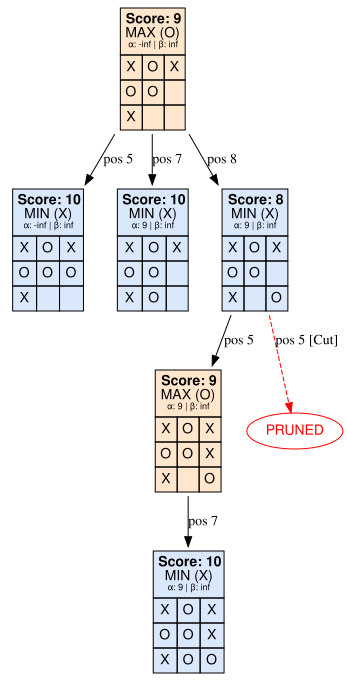

In [31]:
def visualize_alpha_beta_tree(root_state, current_player):
    """
    Generates a decision tree showing alpha-beta pruned branches and final evaluations.
    """
    dot = graphviz.Digraph('AlphaBetaTree', comment='Alpha-Beta Decision Tree')
    dot.attr(rankdir='TB')
    dot.attr('node', fontname='Helvetica', shape='none')

    root_state = [x if x != '' else ' ' for x in root_state]

    def build_tree(state, player, alpha, beta, parent_node_id=None, move_label=None):
        state_str = "".join(state)
        winner = check_winner(state)

        is_maximizing = (player == 'O')
        score = alpha_beta(state, 0, alpha, beta, is_maximizing)

        node_color = "#FFE6CC" if is_maximizing else "#DAE8FC"
        player_role = "MAX (O)" if is_maximizing else "MIN (X)"

        node_label = f"""<
        <TABLE BORDER="0" CELLBORDER="1" CELLSPACING="0" CELLPADDING="4" BGCOLOR="{node_color}">
          <TR><TD COLSPAN="3"><B>Score: {score}</B><BR/>{player_role}<BR/><FONT POINT-SIZE="9">α: {alpha} | β: {beta}</FONT></TD></TR>
          <TR>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[0] if state[0] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[1] if state[1] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[2] if state[2] != ' ' else '&nbsp;'}</TD>
          </TR>
          <TR>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[3] if state[3] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[4] if state[4] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[5] if state[5] != ' ' else '&nbsp;'}</TD>
          </TR>
          <TR>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[6] if state[6] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[7] if state[7] != ' ' else '&nbsp;'}</TD>
            <TD WIDTH="15" HEIGHT="15" ALIGN="CENTER">{state[8] if state[8] != ' ' else '&nbsp;'}</TD>
          </TR>
        </TABLE>
        >"""

        node_id = str(abs(hash(state_str + str(parent_node_id))))
        dot.node(node_id, label=node_label)

        if parent_node_id:
            dot.edge(parent_node_id, node_id, label=move_label)

        if winner is not None:
            return

        next_player = 'X' if player == 'O' else 'O'
        for i in range(9):
            if state[i] == ' ':
                next_state = list(state)
                next_state[i] = player

                # If checking a maximizing branch
                if is_maximizing:
                    # Alpha-Beta logic check for visualization tracking
                    build_tree(next_state, next_player, alpha, beta, node_id, f"pos {i}")
                    # Simulated/Calculated update tracking for visual nodes
                    alpha = max(alpha, score)
                else:
                    build_tree(next_state, next_player, alpha, beta, node_id, f"pos {i}")
                    beta = min(beta, score)

                if beta <= alpha:
                    # Add a visual cutoff node to indicate pruning happened
                    prune_id = f"pruned_{node_id}_{i}"
                    dot.node(prune_id, label="PRUNED", fontcolor="red", shape="ellipse", color="red")
                    dot.edge(node_id, prune_id, label=f"pos {i} [Cut]", color="red", style="dashed")
                    break

    build_tree(root_state, current_player, float('-inf'), float('inf'))
    return dot

# Visualize alpha-beta pruned decision tree on demo state
root_board_demo = [
    'X', 'O', 'X',
    'O', 'O', ' ',
    'X', ' ', ' '
]

print("Visualizing Alpha-Beta Pruning decision tree:")
display(visualize_alpha_beta_tree(root_board_demo, 'O'))